2.1

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [41]:
df = pd.read_csv('../../course_assignments/homework9/noisy_curvefit_data.csv')

In [42]:
print(df.shape) # 100 rows, 6 columns
print(df.head(5))
print(df.tail(5))
print(df.columns) # 'x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5'

(100, 6)
          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850
Index(['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5'],
      dtype='str')


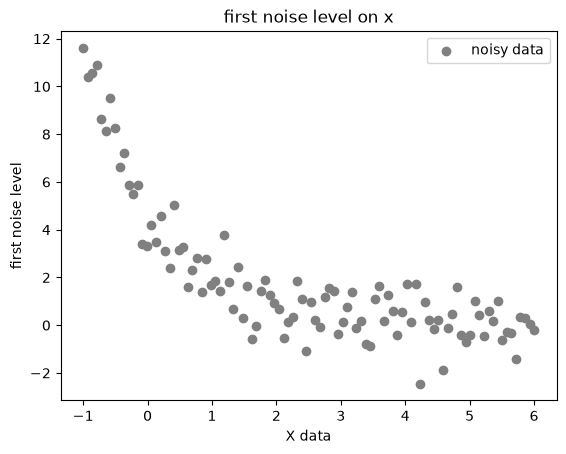

In [43]:
plt.scatter(df['x'], df['y_noise_1'], color = 'grey', label = 'noisy data')
plt.xlabel('X data')
plt.ylabel('first noise level')
plt.title('first noise level on x')
plt.legend()
plt.show()

2.2

In [44]:
def model(x, A, k):
    return A * np.exp(-k * x)

In [45]:
p0 = [1, 1]
popt, pcov = curve_fit(model, df['x'], df['y_noise_1'], p0=p0)

In [46]:
A_fit, k_fit = popt

In [47]:
f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)"

'Fit: y = 4.71 * e^(-0.92 * x)'

In [48]:
residuals = df['y_noise_1'] - model(df['x'], A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(df['x']) - len(popt)
chi2_reduced = chi2 / dof

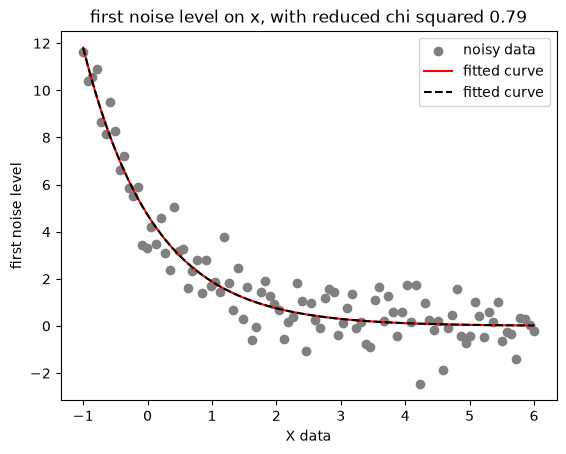

In [49]:
plt.scatter(df['x'], df['y_noise_1'], color = 'grey', label = 'noisy data')
plt.plot(df['x'], model(df['x'], A_fit, k_fit), color = 'red', label = 'fitted curve')
plt.plot(df['x'], model(df['x'], A_fit, k_fit), color = 'black', linestyle = '--', label = 'fitted curve')
plt.xlabel('X data')
plt.ylabel('first noise level')
plt.title(f'first noise level on x, with reduced chi squared {chi2_reduced:.2f}')
plt.legend()
plt.show()

2.3

In [50]:
def fit_model(x, y):
    p0 = [1, 1]
    popt, pcov = curve_fit(model, x, y, p0=p0)
    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return A_fit, k_fit, chi2_reduced

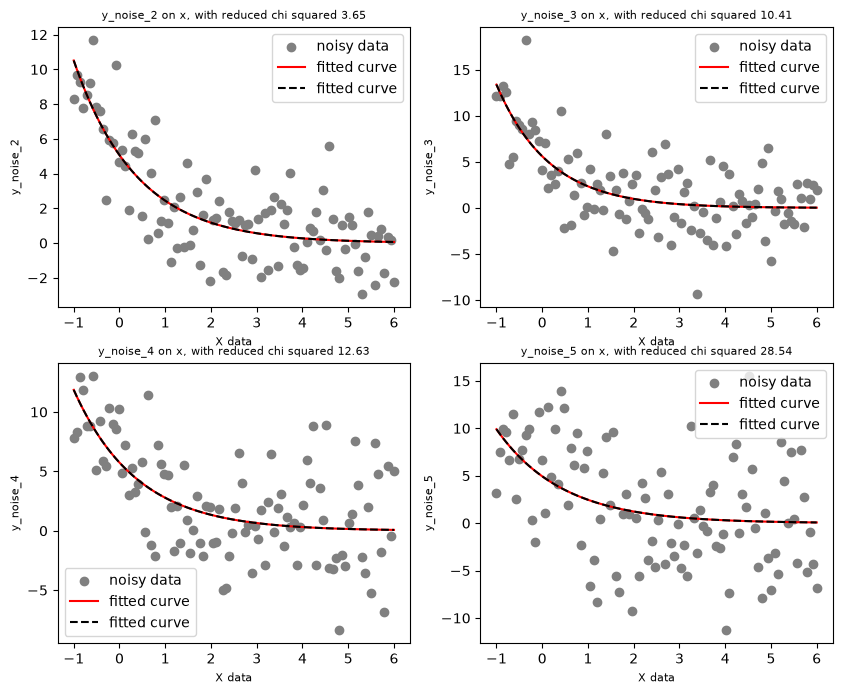

In [51]:
fig, axs = plt.subplots(2, 2, figsize = (10, 8))
list_axs = [axs[0, 0], axs[0, 1], axs[1, 0], axs[1, 1]]
list_y = ['y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']
for a, y in zip(list_axs, list_y):
    A_fit, k_fit, chi2_reduced = fit_model(df['x'], df[y])
    a.scatter(df['x'], df[y], color = 'grey', label = 'noisy data')
    a.plot(df['x'], model(df['x'], A_fit, k_fit), color = 'red', label = 'fitted curve')
    a.plot(df['x'], model(df['x'], A_fit, k_fit), color = 'black', linestyle = '--', label = 'fitted curve')
    a.legend()
    a.set_xlabel('X data', fontsize = 8)
    a.set_ylabel(y,  fontsize = 8)
    a.set_title(f'{y} on x, with reduced chi squared {chi2_reduced:.2f}', fontsize = 8)

In [52]:
# As noise level increase, the fitted curve don't change as random errors don't change the best fit
# As noise level increase, the reduced chi-squared increases as it describes how well the curve is close to data

In [53]:
A = []; k = []; c = []
for i in ['y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']:
    A_fit, k_fit, chi2_reduced = fit_model(df['x'], df[y])
    A.append(A_fit); k.append(k_fit); c.append(chi2_reduced)

df_ans = {
    'Noise_level': [1,2,3,4,5],
    'A_fit': A,
    'k_fit': k,
    'Reduced_chi_squared': c
}

In [54]:
df.to_csv("noisy_parameters.csv", index=False)